# 01 — Bank Marketing | Exploratory Data Analysis

**Objective:** Predict whether a customer subscribes to a term deposit (`y`) using information available **before** a marketing call. **This notebook investigates data; it does not train a model.**

**Data:** [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing), `bank-additional-full.csv` (41,188 records; source order follows time, May 2008–Nov 2010). The repository convention is `data/raw/bank.csv`, extracted from that precise archive member—not the older `bank.csv` variant.

**Why we care:** leakage, shift over time, class imbalance and data contracts are deployment problems as much as modeling problems.

**Run:** from the repository root, `uv run --group train jupyter lab`, open this notebook. Dependencies: `pandas`, `numpy`, `matplotlib`, `scikit-learn` (and JupyterLab).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works whether Jupyter starts in the repository root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / "data" / "raw" / "bank.csv").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "raw" / "bank.csv"
assert DATA.exists(), f"Dataset not found: {DATA}. Download and extract the UCI bank-additional-full.csv first."

raw = pd.read_csv(DATA, sep=";")
assert set(raw["y"].unique()) == {"yes", "no"}
assert raw.shape[1] == 21, "Expected 20 input features + target (bank-additional-full.csv)"
print(f"Rows: {len(raw):,} | Columns: {raw.shape[1]} | File: {DATA}")
display(raw.head(3))

Rows: 41,188 | Columns: 21 | File: /home/chaka/projects/ml_cloudrun_demo/data/raw/bank.csv


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 1 — Data contract and prediction timing

The **decision point** is *before the call*. The target is whether the customer eventually subscribes. `duration` is known only once the call is finished: **drop it**. Fields about the current contact (`month`, `day_of_week`, `campaign`, `contact`) and macroeconomic indicators require a clear definition of what is actually available at prediction time. Treat those as **conditional**, not automatically safe; an operational model may exclude or replace them.

UCI uses `"unknown"` strings in categorical columns; `pdays == 999` means not previously contacted. Neither necessarily appears as a pandas `NaN`. No preprocessing should be fitted before splitting.

In [2]:
print("Dtypes:")
display(raw.dtypes.rename("dtype").to_frame())
print("Target values:", raw["y"].value_counts(dropna=False).to_dict())
print("Exact duplicate rows:", int(raw.duplicated().sum()))
print("Actual null cells:", int(raw.isna().sum().sum()))

# Audit presence of expected fields without silently changing them.
assert {"duration", "pdays", "job", "education", "y"} <= set(raw.columns)

Dtypes:


,dtype
age,int64
job,str
marital,str
education,str
default,str
housing,str
loan,str
contact,str
month,str
day_of_week,str


Target values: {'no': 36548, 'yes': 4640}
Exact duplicate rows: 12
Actual null cells: 0


## 2 — Create chronological development / validation / test segments

The original UCI `bank-additional-full.csv` is date-ordered, but does not provide a full per-row timestamp. A **row-order split** is therefore a *chronological proxy*, not a verified date-based split. We will explore **development (first 70%) only**. Validation (next 15%) and test (last 15%) are reserved for future model selection/final evaluation, respectively. No decisions should use their target distributions during EDA.

In a real deployment we would use genuine event timestamps and, if customers repeat, customer-level grouping or leakage controls.

In [3]:
n = len(raw)
train_end, valid_end = int(n * .70), int(n * .85)
dev = raw.iloc[:train_end].copy()
valid_index = raw.index[train_end:valid_end]
test_index = raw.index[valid_end:]
assert len(dev) + len(valid_index) + len(test_index) == n
assert max(dev.index) < min(valid_index) < min(test_index)
print(f"Development: {len(dev):,} | Validation reserved: {len(valid_index):,} | Test reserved: {len(test_index):,}")
# Inspect no later segment's target or feature statistics in this notebook.

Development: 28,831 | Validation reserved: 6,178 | Test reserved: 6,179


## 3 — Data quality audit (development only)

Check true null values, categorical `unknown` sentinel rates, numeric outliers, uniqueness, duplicates and target coverage. Do not drop duplicates automatically: a row may represent a repeated legitimate call, and there is no unique customer ID to prove otherwise.

In [4]:
feature_cols = [col for col in dev.columns if col != "y"]
cat_cols = dev[feature_cols].select_dtypes(include=["object", "category", "string"]).columns.tolist()
num_cols = dev[feature_cols].select_dtypes(include="number").columns.tolist()

quality = pd.DataFrame({
    "dtype": dev[feature_cols].dtypes.astype(str),
    "null_pct": dev[feature_cols].isna().mean().mul(100).round(2),
    "distinct": dev[feature_cols].nunique(dropna=False),
})
quality["unknown_pct"] = [
    round(100 * dev[col].eq("unknown").mean(), 2) if col in cat_cols else 0.0
    for col in feature_cols
]
display(quality.sort_values(["unknown_pct", "null_pct"], ascending=False))
print(f"Categorical ({len(cat_cols)}):", cat_cols)
print(f"Numerical ({len(num_cols)}):", num_cols)
print("Duplicate development rows:", int(dev.duplicated().sum()))
print("pdays == 999 (%):", round(100 * dev["pdays"].eq(999).mean(), 2))

,dtype,null_pct,distinct,unknown_pct
default,str,0.0,3,25.33
education,str,0.0,8,4.10
housing,str,0.0,3,2.41
loan,str,0.0,3,2.41
job,str,0.0,12,0.86
marital,str,0.0,4,0.17
age,int64,0.0,63,0.00
contact,str,0.0,2,0.00
month,str,0.0,9,0.00
day_of_week,str,0.0,5,0.00


Categorical (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numerical (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Duplicate development rows: 9
pdays == 999 (%): 99.82


## 4 — Target imbalance and baseline intuition

`yes` is the positive class. Accuracy alone is misleading when positive cases are less frequent. Later use **average precision (PR-AUC)**, ROC-AUC, calibrated probabilities and a business-aligned threshold. The development-class prevalence is an informative baseline, not a final performance metric.

Development positive rate: 5.57%


,count,share
y,,
no,27225,0.944296
yes,1606,0.055704


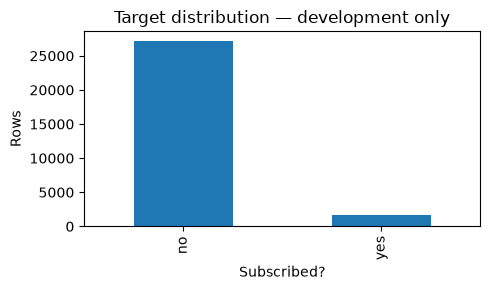

In [5]:
counts = dev["y"].value_counts().reindex(["no", "yes"], fill_value=0)
rate = dev["y"].eq("yes").mean()
print(f"Development positive rate: {rate:.2%}")
display(pd.DataFrame({"count": counts, "share": counts / len(dev)}))
fig, ax = plt.subplots(figsize=(5, 3))
counts.plot.bar(ax=ax)
ax.set(title="Target distribution — development only", xlabel="Subscribed?", ylabel="Rows")
plt.tight_layout()
plt.show()

## 5 — Numerical features: ranges and outliers

Not all numeric variables have the same meaning: `pdays=999` is a **sentinel**, not a very long elapsed time. Some numeric fields have strong skew. Investigate before choosing winsorization, transformations or scaling; **fit any such transformations only on training data**.

,count,mean,std,min,1%,50%,95%,99%,max
age,28831.0,40.177483,9.335439,18.000,24.000,39.000,57.000,59.000,95.000
duration,28831.0,253.768756,262.985377,0.000,13.000,172.000,755.000,1284.400,4918.000
campaign,28831.0,2.768270,3.111751,1.000,1.000,2.000,8.000,17.000,56.000
pdays,28831.0,997.172592,42.583054,0.000,999.000,999.000,999.000,999.000,999.000
previous,28831.0,0.035899,0.192456,0.000,0.000,0.000,0.000,1.000,3.000
emp.var.rate,28831.0,1.000409,0.747091,-1.800,-1.800,1.400,1.400,1.400,1.400
cons.price.idx,28831.0,93.810004,0.416240,92.756,92.843,93.918,94.465,94.465,94.465
cons.conf.idx,28831.0,-39.792935,3.369460,-50.000,-47.100,-41.800,-36.100,-36.100,-36.100
euribor3m,28831.0,4.685469,0.704179,1.410,1.415,4.957,4.967,4.968,5.045
nr.employed,28831.0,5208.861153,28.165318,5099.100,5099.100,5228.100,5228.100,5228.100,5228.100


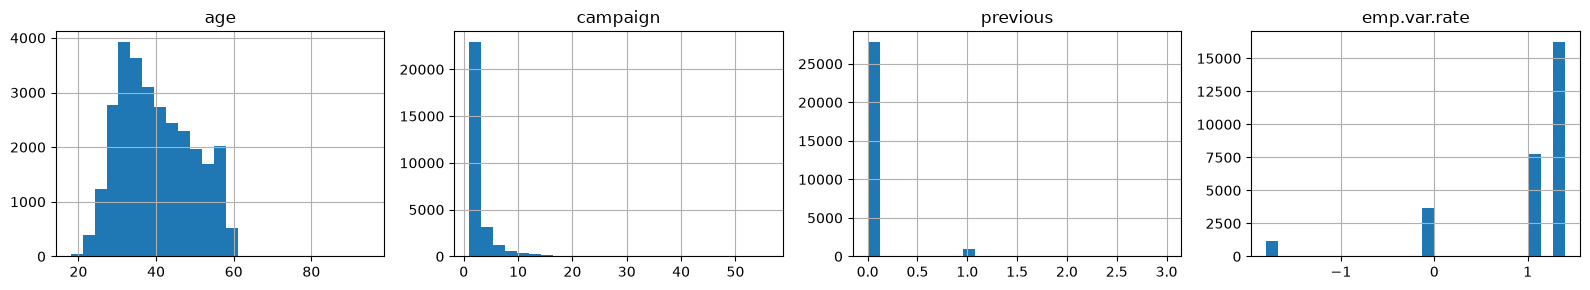

In [6]:
display(dev[num_cols].describe(percentiles=[.01, .5, .95, .99]).T)
plot_cols = [x for x in ["age", "campaign", "previous", "emp.var.rate"] if x in dev.columns]
fig, axes = plt.subplots(1, len(plot_cols), figsize=(4 * len(plot_cols), 3))
axes = np.atleast_1d(axes)
for ax, col in zip(axes, plot_cols):
    dev[col].hist(ax=ax, bins=25)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 6 — Categorical features and rare values

Review category frequencies, including literal `unknown`. For production, `OneHotEncoder(handle_unknown="ignore")` handles unseen categories without breaking inference. Whether to keep `"unknown"` as a meaningful value or convert it to missing is a **domain decision** to test, not a default cleanup.

In [7]:
for col in ["job", "education", "marital", "contact", "poutcome"]:
    print(f"\n{col} (top values):")
    display(dev[col].value_counts(dropna=False).head(12).to_frame("count"))


job (top values):


,count
job,
admin.,7107
blue-collar,6705
technician,5054
services,2826
management,2096
entrepreneur,1105
self-employed,1043
retired,879
housemaid,838



education (top values):


,count
education,
university.degree,8345
high.school,6459
basic.9y,4329
professional.course,3795
basic.4y,3051
basic.6y,1655
unknown,1183
illiterate,14



marital (top values):


,count
marital,
married,18204
single,7203
divorced,3375
unknown,49



contact (top values):


,count
contact,
cellular,15038
telephone,13793



poutcome (top values):


,count
poutcome,
nonexistent,27829
failure,952
success,50


## 7 — Exploratory relationships (NOT feature selection on test)

Compare development-only subscription rates for selected fields. These are **observational associations, not causal effects**; large/small groups can differ in many ways. Avoid selecting features based solely on unvalidated group rates.

In [8]:
for col in ["job", "education", "poutcome"]:
    rates = (
        dev.assign(subscribed=dev["y"].eq("yes").astype(int))
           .groupby(col, observed=True)["subscribed"]
           .agg(["size", "mean"])
           .rename(columns={"size": "n", "mean": "positive_rate"})
           .sort_values("n", ascending=False)
    )
    print(col)
    display(rates.head(12).round(3))

job


,n,positive_rate
job,,
admin.,7107,0.059
blue-collar,6705,0.050
technician,5054,0.054
services,2826,0.051
management,2096,0.061
entrepreneur,1105,0.054
self-employed,1043,0.059
retired,879,0.092
housemaid,838,0.036


education


,n,positive_rate
education,,
university.degree,8345,0.064
high.school,6459,0.055
basic.9y,4329,0.053
professional.course,3795,0.052
basic.4y,3051,0.045
basic.6y,1655,0.054
unknown,1183,0.051
illiterate,14,0.143


poutcome


,n,positive_rate
poutcome,,
nonexistent,27829,0.055
failure,952,0.059
success,50,0.140


## 8 — Leakage and availability register

| Field | Before-call status | Decision |
|---|---|---|
| `duration` | Outcome of current call | **Exclude** (leakage) |
| `pdays` | Prior campaign history | Keep only with sentinel handling (`999`) |
| `previous`, `poutcome` | Prior history | Likely usable, subject to actual system availability |
| `month`, `day_of_week`, `contact`, `campaign` | Current contact information | **Verify** scheduling/event semantics |
| Macroeconomic fields | Dated values | **Verify** historical publication/availability and avoid future data |
| `y` | Prediction target | Never an input |

**Interpretation:** the correct feature set is determined by the decision point and production data contracts, not just model importance.

In [9]:
LEAKY = {"duration", "y"}
features_candidate = [col for col in raw.columns if col not in LEAKY]
assert "duration" not in features_candidate
assert "y" not in features_candidate
print("Candidate inputs pending availability review:", features_candidate)
print("Count:", len(features_candidate))

Candidate inputs pending availability review: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Count: 19


## 9 — Findings and decisions to carry into production

1. **Objective:** score before the call; never send `duration` to the API.
2. **Validation:** prioritize held-out later observations; row ordering is only a proxy for event time, so document its limitations.
3. **Sentinels:** treat `pdays=999` deliberately; audit categorical `"unknown"` without conflating it with pandas nulls.
4. **Feature contract:** confirm availability of current-contact and macroeconomic fields before freezing API schema.
5. **Metrics:** prioritize average precision / PR curves plus ROC-AUC, recall at a business-selected threshold, probability calibration and lift versus random targeting.
6. **Reproducibility:** preserve raw data unmodified, create fitted transformations only in `Pipeline` after splitting and save the complete fitted pipeline artifact.
7. **Privacy:** this public dataset has no stable customer identifier; it cannot establish customer-group leakage safety.

### Next deliverable
`src/ml_cloudrun_demo/train.py`: reproduce the documented split, build a `ColumnTransformer` (numerical imputation/scaling; categorical imputation/one-hot) within an sklearn `Pipeline`, evaluate on validation, freeze a decision threshold, and run the **test set once**. Store `model.joblib` plus metrics, schema, and environment/version metadata.

### Sources
- [UCI Bank Marketing (dataset metadata and field definitions)](https://archive.ics.uci.edu/dataset/222/bank+marketing)
- [scikit-learn: Common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html)